<a href="https://colab.research.google.com/github/MarokoVo/Data-analytics/blob/main/lab2/lab2_analisys_python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
%matplotlib inline

df = pd.read_csv("auto_cleaned.csv")
df.head()

,symboling,normalized-losses,make,fueltype,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,aspiration-std,aspiration-turbo
0,3,122,alfa-romero,gas,two,convertible,rwd,front,88.6,168.8,...,3.47,2.68,9.0,111,5000.0,21,27,13495.0,1,0
1,3,122,alfa-romero,gas,two,convertible,rwd,front,88.6,168.8,...,3.47,2.68,9.0,111,5000.0,21,27,16500.0,1,0
2,1,122,alfa-romero,gas,two,hatchback,rwd,front,94.5,171.2,...,2.68,3.47,9.0,154,5000.0,19,26,16500.0,1,0
3,2,164,audi,gas,four,sedan,fwd,front,99.8,176.6,...,3.19,3.40,10.0,102,5500.0,24,30,13950.0,1,0
4,2,164,audi,gas,four,sedan,4wd,front,99.4,176.6,...,3.19,3.40,8.0,115,5500.0,18,22,17450.0,1,0


1. Кореляція між bore, stroke, compression-ratio, horsepower

In [3]:
df[["bore", "stroke", "compression-ratio", "horsepower"]].corr()

,bore,stroke,compression-ratio,horsepower
bore,1.000000,-0.055909,0.005201,0.575707
stroke,-0.055909,1.000000,0.186105,0.088133
compression-ratio,0.005201,0.186105,1.000000,-0.205717
horsepower,0.575707,0.088133,-0.205717,1.000000


2. Кореляція між stroke та price

,stroke,price
stroke,1.000000,0.082095
price,0.082095,1.000000


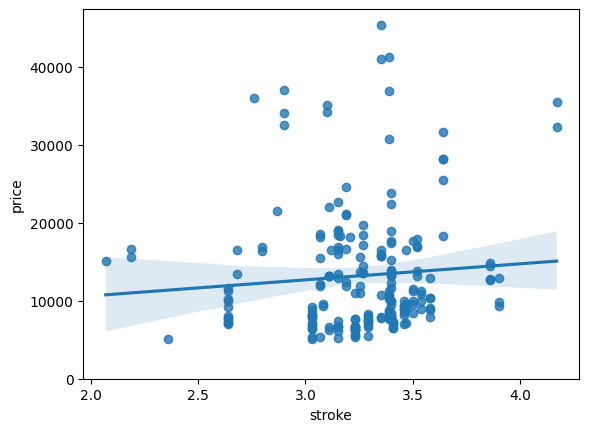

In [4]:
sns.regplot(x="stroke", y="price", data=df)
plt.ylim(0,)
df[["stroke", "price"]].corr()

3. Чи очікуєте лінійну залежність?
ні не очікую , коефіцієнт кореляції між «stroke» та «price» становить близько 0,08, це дуже близько до нуля, тоді зв'язок між змінними дуже слабкий.




4. Середня ціна за body-style (groupby)

In [5]:
df_group = df[["body-style", "price"]]
df_group.groupby("body-style", as_index=False).mean()

,body-style,price
0,convertible,21890.500000
1,hardtop,22208.500000
2,hatchback,10050.289410
3,sedan,14433.658945
4,wagon,12371.960000


5. Пірсон і P-value для wheel-base та price

In [6]:
pearson_coef, p_value = stats.pearsonr(df["wheel-base"], df["price"])
print("Коефіцієнт Пірсона:", pearson_coef, " P-value:", p_value)

Коефіцієнт Пірсона: 0.5831681499789549  P-value: 4.5276255456863095e-20


6. Те саме для horsepower та price

In [7]:
pearson_coef, p_value = stats.pearsonr(df["horsepower"], df["price"])
print("Коефіцієнт Пірсона:", pearson_coef, " P-value:", p_value)

Коефіцієнт Пірсона: 0.7579459704465277  P-value: 1.590831957220177e-39


7. Дисперсійний аналіз (ANOVA) для кількох пар, наприклад drive-wheels і price

In [8]:
grouped = df[["drive-wheels", "price"]].groupby("drive-wheels")

f_val, p_val = stats.f_oneway(
    grouped.get_group("fwd")["price"],
    grouped.get_group("rwd")["price"],
    grouped.get_group("4wd")["price"])
print("Усі три групи: F =", f_val, " P =", p_val)

f_val, p_val = stats.f_oneway(grouped.get_group("fwd")["price"], grouped.get_group("rwd")["price"])
print("fwd і rwd: F =", f_val, " P =", p_val)

f_val, p_val = stats.f_oneway(grouped.get_group("4wd")["price"], grouped.get_group("rwd")["price"])
print("4wd і rwd: F =", f_val, " P =", p_val)

Усі три групи: F = 67.50366682669122  P = 3.539270791604724e-23
fwd і rwd: F = 129.41115759339715  P = 2.6524240289951807e-23
4wd і rwd: F = 8.87906543865251  P = 0.00378273257813761


In [9]:
grouped2 = df[["body-style", "price"]].groupby("body-style")

f_val, p_val = stats.f_oneway(
    grouped2.get_group("sedan")["price"],
    grouped2.get_group("hatchback")["price"],
    grouped2.get_group("wagon")["price"])
print("sedan, hatchback, wagon: F =", f_val, " P =", p_val)

sedan, hatchback, wagon: F = 8.55006348319596  P = 0.00027928041710135413
